# Phase 4: Traditional Machine Learning Baseline Classification
## Intelligent Consumer Complaint Classification & Prioritization Using NLP

In Phases 1–3, we acquired `liri-uzh/cfpb-complaints-mini`, performed thorough Exploratory Data Analysis, and built a reproducible preprocessing pipeline producing:
- `data/processed/train_processed.csv` (`6,363` cleaned, conflict-free rows across `7` classes)
- `data/processed/test_processed.csv` (`1,635` untouched held-out test rows across `7` classes)

In Phase 4, we systematically benchmark traditional sparse-feature machine learning classifiers under strict zero-leakage cross-validation before advancing to deep learning in Phase 5.

## 2. Experimental Objectives

1. **Baseline Benchmark (Experiment 1):** Evaluate 5 classical linear/probabilistic classifiers (`MultinomialNB`, `ComplementNB`, `LogisticRegression`, `LinearSVC`, `SGDClassifier`) using Word TF-IDF on `text_standard`.
2. **Preprocessing Comparison (Experiment 2):** Test whether `text_raw`, `text_minimal`, `text_standard`, `text_stopword`, `text_lemmatized`, or `text_stemmed` yields the strongest cross-validated Macro-F1 across the top 3 models.
3. **Feature Representation Comparison (Experiment 3):** Compare Word TF-IDF `(1, 2)`, Character `char_wb` TF-IDF `(3, 5)`, and combined Word + Character `FeatureUnion` across the top 2 models.
4. **Hyperparameter Tuning (Experiment 4):** Tune the strongest model family/families via `GridSearchCV` (`scoring="f1_macro"`) strictly on `train`.
5. **Final Test Evaluation, Error Analysis & Interpretability:** Fit the single selected pipeline on full cleaned `train`, evaluate **once** on held-out `test`, inspect misclassifications and top positive class weights, and persist the full `Pipeline` artifact via `joblib`.

## 3. Imports and Configuration

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 150

PROJECT_ROOT = Path("..").resolve()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = Path("Experiment_9/complaint-classification").resolve()

DATA_PROC_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_ML_DIR = PROJECT_ROOT / "reports" / "ml_baselines"
FIGURES_ML_DIR = PROJECT_ROOT / "reports" / "figures" / "ml_baselines"
MODELS_DIR = PROJECT_ROOT / "models"

for d in (REPORTS_ML_DIR, FIGURES_ML_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"Project Root : {PROJECT_ROOT}")
print(f"Reports Dir  : {REPORTS_ML_DIR}")
print(f"Figures Dir  : {FIGURES_ML_DIR}")
print(f"Models Dir   : {MODELS_DIR}")

Project Root : D:\SEM 7\CLNLP\LAB\Experiment_9\complaint-classification
Reports Dir  : D:\SEM 7\CLNLP\LAB\Experiment_9\complaint-classification\reports\ml_baselines
Figures Dir  : D:\SEM 7\CLNLP\LAB\Experiment_9\complaint-classification\reports\figures\ml_baselines
Models Dir   : D:\SEM 7\CLNLP\LAB\Experiment_9\complaint-classification\models


## 4. Load Prepared Datasets

We load `train_processed.csv` and `test_processed.csv`. Only `train_processed.csv` will be used for cross-validation, preprocessing comparison, feature selection, and hyperparameter tuning.

In [2]:
df_train = pd.read_csv(DATA_PROC_DIR / "train_processed.csv")
df_test = pd.read_csv(DATA_PROC_DIR / "test_processed.csv")

print(f"Train Processed Shape: {df_train.shape}")
print(f"Test Processed Shape : {df_test.shape}")
print(f"Columns: {df_train.columns.tolist()}")

Train Processed Shape: (6363, 8)
Test Processed Shape : (1635, 8)
Columns: ['text_raw', 'text_minimal', 'text_standard', 'text_stopword', 'text_lemmatized', 'text_stemmed', 'label', 'product_raw']


## 5. Verify Datasets

In [3]:
assert int(df_train.isnull().sum().sum()) == 0, "Nulls found in train"
assert int(df_test.isnull().sum().sum()) == 0, "Nulls found in test"
assert len(set(df_train["text_raw"]).intersection(set(df_test["text_raw"]))) == 0, "Train-test overlap detected!"

print("Dataset verification passed: 0 nulls, 0 train-test overlap.")
print("\nTrain Class Counts:")
print(df_train["label"].value_counts().sort_index())

Dataset verification passed: 0 nulls, 0 train-test overlap.

Train Class Counts:
label
bank_account        960
credit_card         848
credit_reporting    750
debt_collection     926
money_transfer      959
mortgage            960
student_loan        960
Name: count, dtype: int64


## 6. Define Target Labels

In [4]:
LABELS = sorted(df_train["label"].unique().tolist())
print(f"Target Classes ({len(LABELS)}): {LABELS}")
y_train = df_train["label"].values
y_test = df_test["label"].values

Target Classes (7): ['bank_account', 'credit_card', 'credit_reporting', 'debt_collection', 'money_transfer', 'mortgage', 'student_loan']


## 7. Evaluation Metrics

- **Primary Metric:** `f1_macro` (Macro-F1) — weights all 7 classes equally.
- **Secondary Metrics:** `accuracy`, `f1_weighted`, `precision_macro`, `recall_macro`, plus per-class precision, recall, and F1.

In [5]:
SCORING = {
    "f1_macro": "f1_macro",
    "accuracy": "accuracy",
    "f1_weighted": "f1_weighted",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
}

def evaluate_pipeline_cv(name: str, pipeline: Pipeline, X, y, cv) -> dict:
    t0 = time.perf_counter()
    res = cross_validate(
        pipeline, X, y, cv=cv, scoring=SCORING, n_jobs=-1, return_train_score=False
    )
    elapsed = time.perf_counter() - t0
    return {
        "Model": name,
        "Macro_F1_Mean": float(np.mean(res["test_f1_macro"])),
        "Macro_F1_Std": float(np.std(res["test_f1_macro"])),
        "Accuracy_Mean": float(np.mean(res["test_accuracy"])),
        "Accuracy_Std": float(np.std(res["test_accuracy"])),
        "Weighted_F1_Mean": float(np.mean(res["test_f1_weighted"])),
        "Weighted_F1_Std": float(np.std(res["test_f1_weighted"])),
        "Precision_Macro_Mean": float(np.mean(res["test_precision_macro"])),
        "Recall_Macro_Mean": float(np.mean(res["test_recall_macro"])),
        "Duration_Sec": round(elapsed, 2),
    }

## 8. Cross-Validation Configuration

We use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` identically across all experiments. Every vectorizer is embedded inside an sklearn `Pipeline` so vocabulary and IDF statistics are fitted solely on each fold's training split.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


## 9. Experiment 1: Word TF-IDF Baseline (`text_standard`)

We benchmark 5 models using `TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True, lowercase=False)` on `text_standard` (which is already lowercased).

In [7]:
def make_word_tfidf(lowercase: bool = False) -> TfidfVectorizer:
    return TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
        lowercase=lowercase,
    )

baseline_models = {
    "MultinomialNB": MultinomialNB(),
    "ComplementNB": ComplementNB(),
    "LogisticRegression": LogisticRegression(max_iter=2000, solver="lbfgs", random_state=RANDOM_STATE),
    "LinearSVC": LinearSVC(random_state=RANDOM_STATE),
    "SGDClassifier": SGDClassifier(loss="hinge", max_iter=2000, tol=1e-3, random_state=RANDOM_STATE),
}

X_train_std = df_train["text_standard"]
exp1_results = []
for model_name, clf in baseline_models.items():
    pipe = Pipeline([("tfidf", make_word_tfidf(lowercase=False)), ("clf", clf)])
    metrics = evaluate_pipeline_cv(model_name, pipe, X_train_std, y_train, cv)
    exp1_results.append(metrics)
    print(f"{model_name:20s} | Macro-F1: {metrics['Macro_F1_Mean']:.4f} ± {metrics['Macro_F1_Std']:.4f} | Acc: {metrics['Accuracy_Mean']:.4f} | {metrics['Duration_Sec']}s")

exp1_df = pd.DataFrame(exp1_results).sort_values("Macro_F1_Mean", ascending=False).reset_index(drop=True)
exp1_df.to_csv(REPORTS_ML_DIR / "model_comparison.csv", index=False)
display(exp1_df.round(4))

MultinomialNB        | Macro-F1: 0.7287 ± 0.0095 | Acc: 0.7438 | 9.28s


ComplementNB         | Macro-F1: 0.7915 ± 0.0082 | Acc: 0.7974 | 7.29s


LogisticRegression   | Macro-F1: 0.8307 ± 0.0078 | Acc: 0.8318 | 20.79s


LinearSVC            | Macro-F1: 0.8421 ± 0.0043 | Acc: 0.8433 | 8.12s


SGDClassifier        | Macro-F1: 0.8388 ± 0.0068 | Acc: 0.8399 | 4.32s


,Model,Macro_F1_Mean,Macro_F1_Std,Accuracy_Mean,Accuracy_Std,Weighted_F1_Mean,Weighted_F1_Std,Precision_Macro_Mean,Recall_Macro_Mean,Duration_Sec
0,LinearSVC,0.8421,0.0043,0.8433,0.0045,0.8433,0.0045,0.8431,0.8422,8.12
1,SGDClassifier,0.8388,0.0068,0.8399,0.0072,0.8399,0.0071,0.8398,0.8388,4.32
2,LogisticRegression,0.8307,0.0078,0.8318,0.0075,0.8318,0.0077,0.8330,0.8302,20.79
3,ComplementNB,0.7915,0.0082,0.7974,0.0083,0.7936,0.0082,0.8059,0.7935,7.29
4,MultinomialNB,0.7287,0.0095,0.7438,0.0091,0.7324,0.0095,0.7817,0.7345,9.28


## 10. Experiment 1: Model Comparison Visualizations

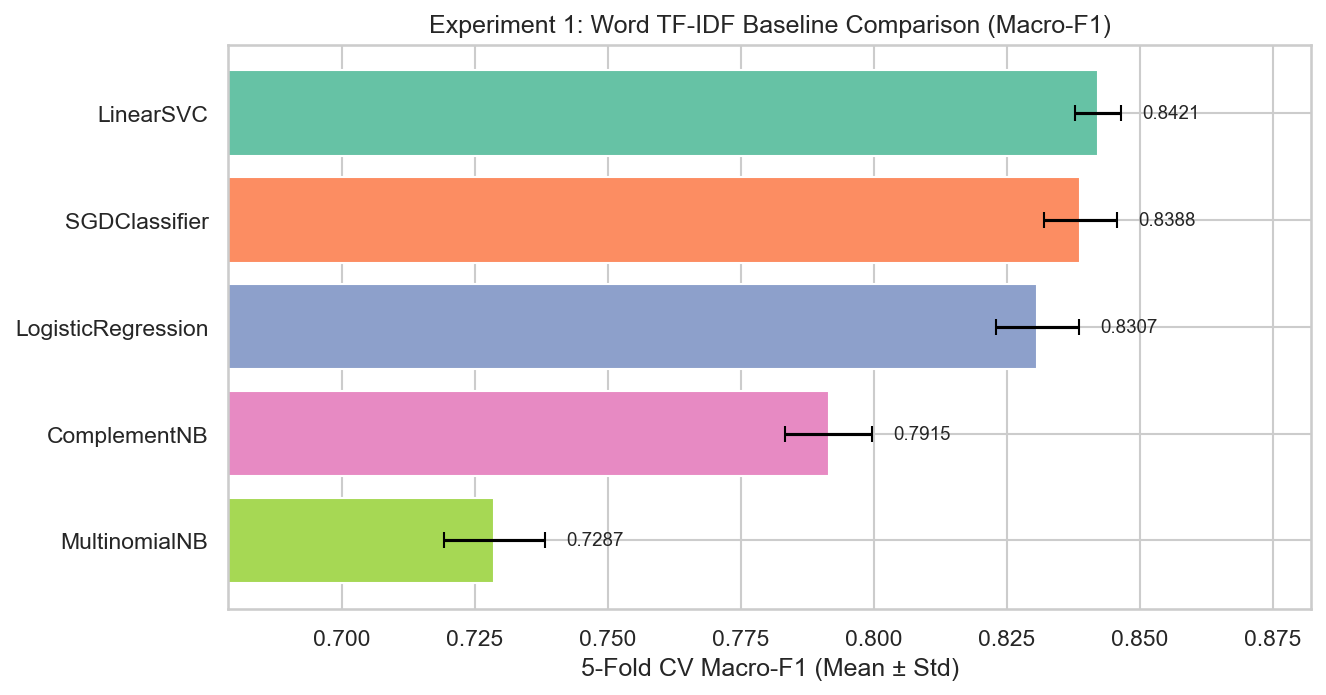

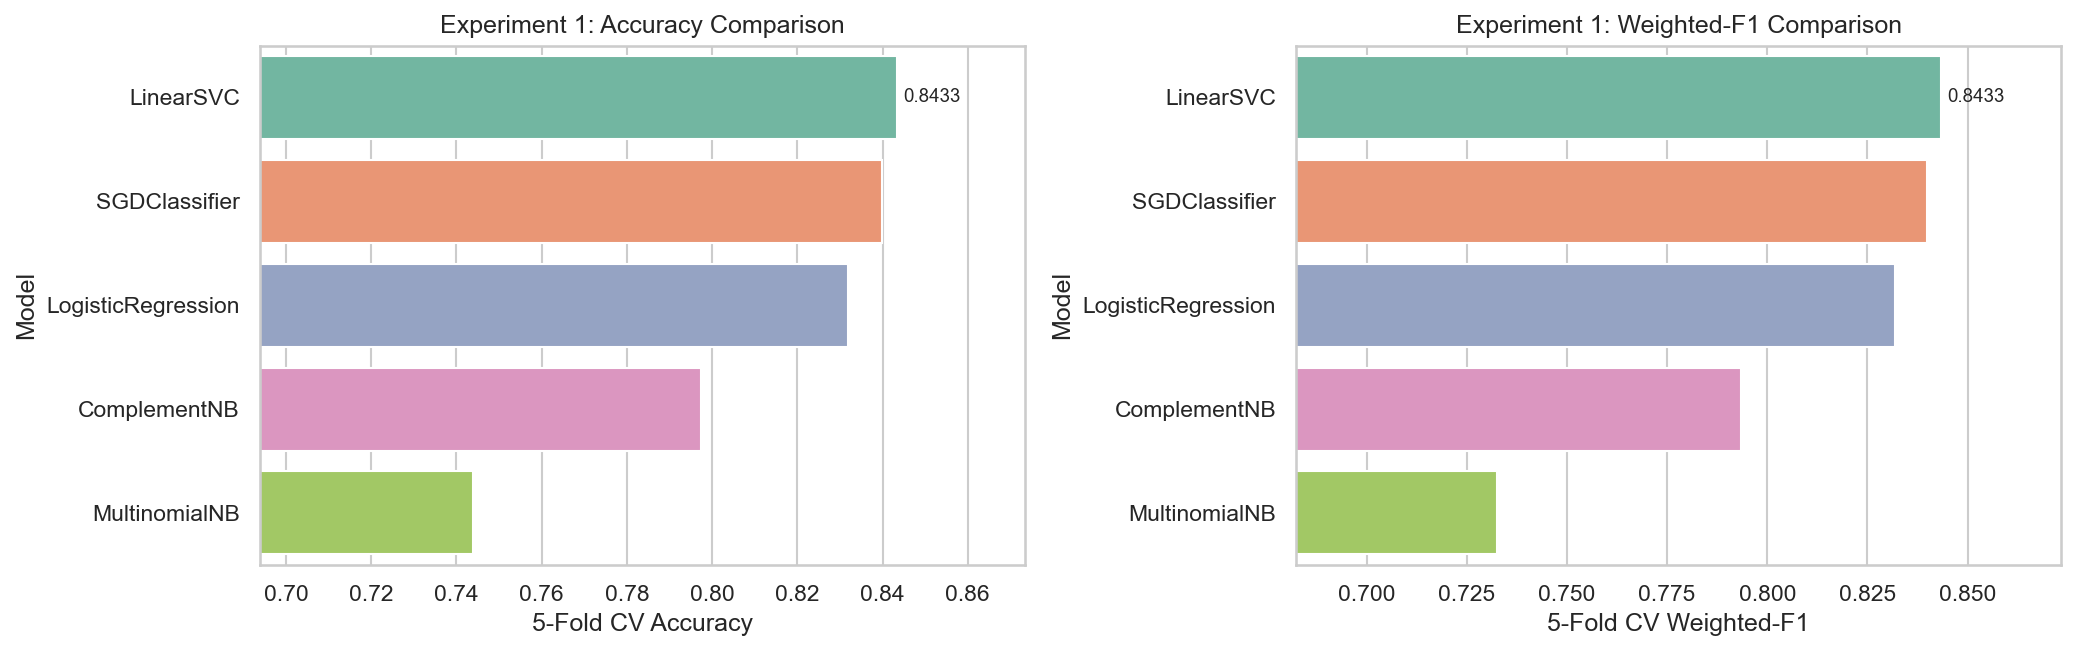

In [8]:
# Macro-F1 with Error Bars
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(exp1_df["Model"], exp1_df["Macro_F1_Mean"], xerr=exp1_df["Macro_F1_Std"], capsize=4, color=sns.color_palette("Set2", len(exp1_df)))
ax.invert_yaxis()
ax.set_xlabel("5-Fold CV Macro-F1 (Mean ± Std)")
ax.set_title("Experiment 1: Word TF-IDF Baseline Comparison (Macro-F1)")
ax.set_xlim(max(0.5, exp1_df["Macro_F1_Mean"].min() - 0.05), min(1.0, exp1_df["Macro_F1_Mean"].max() + 0.04))
for i, row in exp1_df.iterrows():
    ax.text(row["Macro_F1_Mean"] + row["Macro_F1_Std"] + 0.004, i, f"{row['Macro_F1_Mean']:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_ML_DIR / "model_comparison_macro_f1.png", bbox_inches="tight")
plt.show()

# Accuracy & Weighted-F1 Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=exp1_df, y="Model", x="Accuracy_Mean", ax=axes[0], palette="Set2")
axes[0].set_title("Experiment 1: Accuracy Comparison")
axes[0].set_xlabel("5-Fold CV Accuracy")
axes[0].set_xlim(max(0.5, exp1_df["Accuracy_Mean"].min() - 0.05), min(1.0, exp1_df["Accuracy_Mean"].max() + 0.03))
axes[0].bar_label(axes[0].containers[0], fmt="%.4f", padding=3, fontsize=9)

sns.barplot(data=exp1_df, y="Model", x="Weighted_F1_Mean", ax=axes[1], palette="Set2")
axes[1].set_title("Experiment 1: Weighted-F1 Comparison")
axes[1].set_xlabel("5-Fold CV Weighted-F1")
axes[1].set_xlim(max(0.5, exp1_df["Weighted_F1_Mean"].min() - 0.05), min(1.0, exp1_df["Weighted_F1_Mean"].max() + 0.03))
axes[1].bar_label(axes[1].containers[0], fmt="%.4f", padding=3, fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_ML_DIR / "model_comparison_accuracy.png", bbox_inches="tight")
plt.show()

## 11. Detailed Per-Class Evaluation (Best Experiment 1 Model via OOF Predictions)

We generate 5-fold out-of-fold (OOF) predictions for the top-ranked model from Experiment 1 so every training sample is predicted by a model that did not train on it.

Best Experiment 1 Model: LinearSVC


,precision,recall,f1-score,support
bank_account,0.7497,0.7771,0.7632,960.0000
credit_card,0.7953,0.7606,0.7776,848.0000
credit_reporting,0.8307,0.8507,0.8406,750.0000
debt_collection,0.8501,0.8510,0.8505,926.0000
money_transfer,0.7945,0.7821,0.7882,959.0000
mortgage,0.9303,0.9312,0.9308,960.0000
student_loan,0.9457,0.9427,0.9442,960.0000
accuracy,0.8433,0.8433,0.8433,0.8433
macro avg,0.8423,0.8422,0.8421,6363.0000
weighted avg,0.8435,0.8433,0.8433,6363.0000


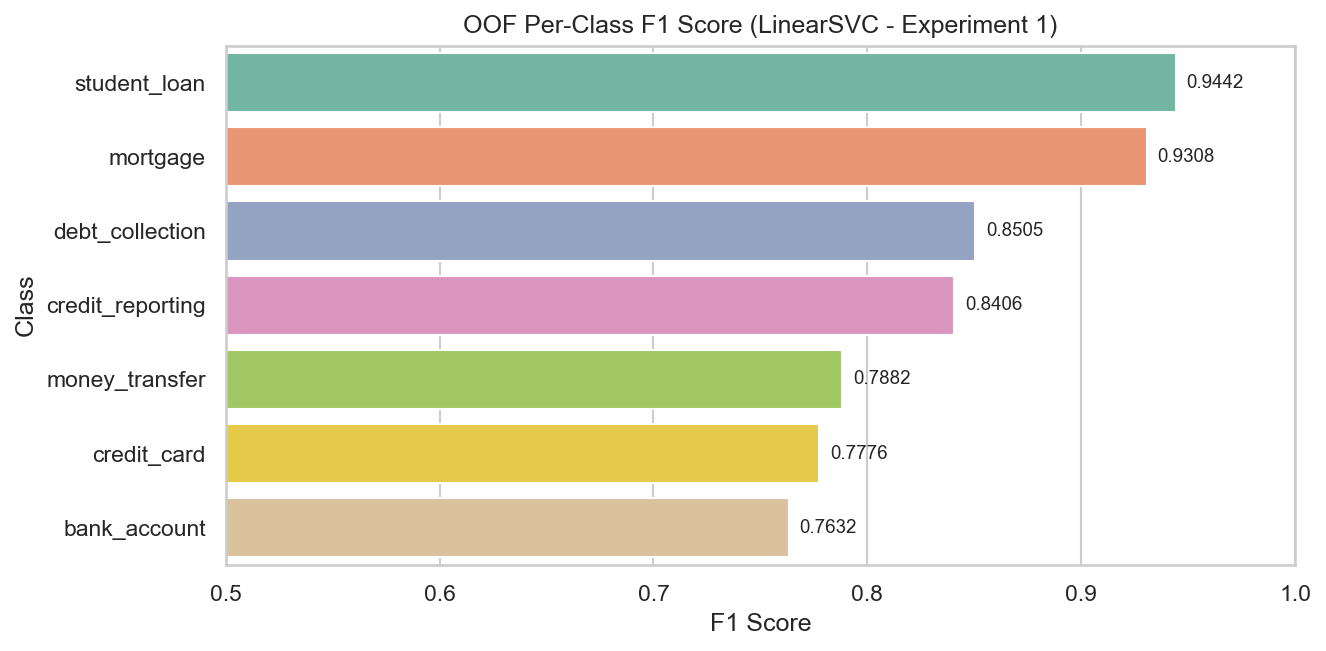

In [9]:
best_exp1_name = exp1_df.iloc[0]["Model"]
best_exp1_clf = clone(baseline_models[best_exp1_name])
best_exp1_pipe = Pipeline([("tfidf", make_word_tfidf(lowercase=False)), ("clf", best_exp1_clf)])

oof_preds = cross_val_predict(best_exp1_pipe, X_train_std, y_train, cv=cv, n_jobs=-1)

oof_report_dict = classification_report(y_train, oof_preds, labels=LABELS, output_dict=True)
oof_report_df = pd.DataFrame(oof_report_dict).T
print(f"Best Experiment 1 Model: {best_exp1_name}")
display(oof_report_df.round(4))

# Per-class F1 bar chart
cls_f1_df = oof_report_df.loc[LABELS, ["precision", "recall", "f1-score"]].reset_index().rename(columns={"index": "Class"})
plt.figure(figsize=(9, 4.5))
sns.barplot(data=cls_f1_df.sort_values("f1-score", ascending=False), y="Class", x="f1-score", palette="Set2")
plt.title(f"OOF Per-Class F1 Score ({best_exp1_name} - Experiment 1)")
plt.xlabel("F1 Score")
plt.xlim(0.5, 1.0)
for i, v in enumerate(cls_f1_df.sort_values("f1-score", ascending=False)["f1-score"]):
    plt.text(v + 0.005, i, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 12. Confusion Matrix Analysis (OOF Predictions)

We inspect both raw counts and row-normalized confusion matrices to identify primary inter-class error pairs (including `credit_reporting` vs. `debt_collection` and any other major confusions).

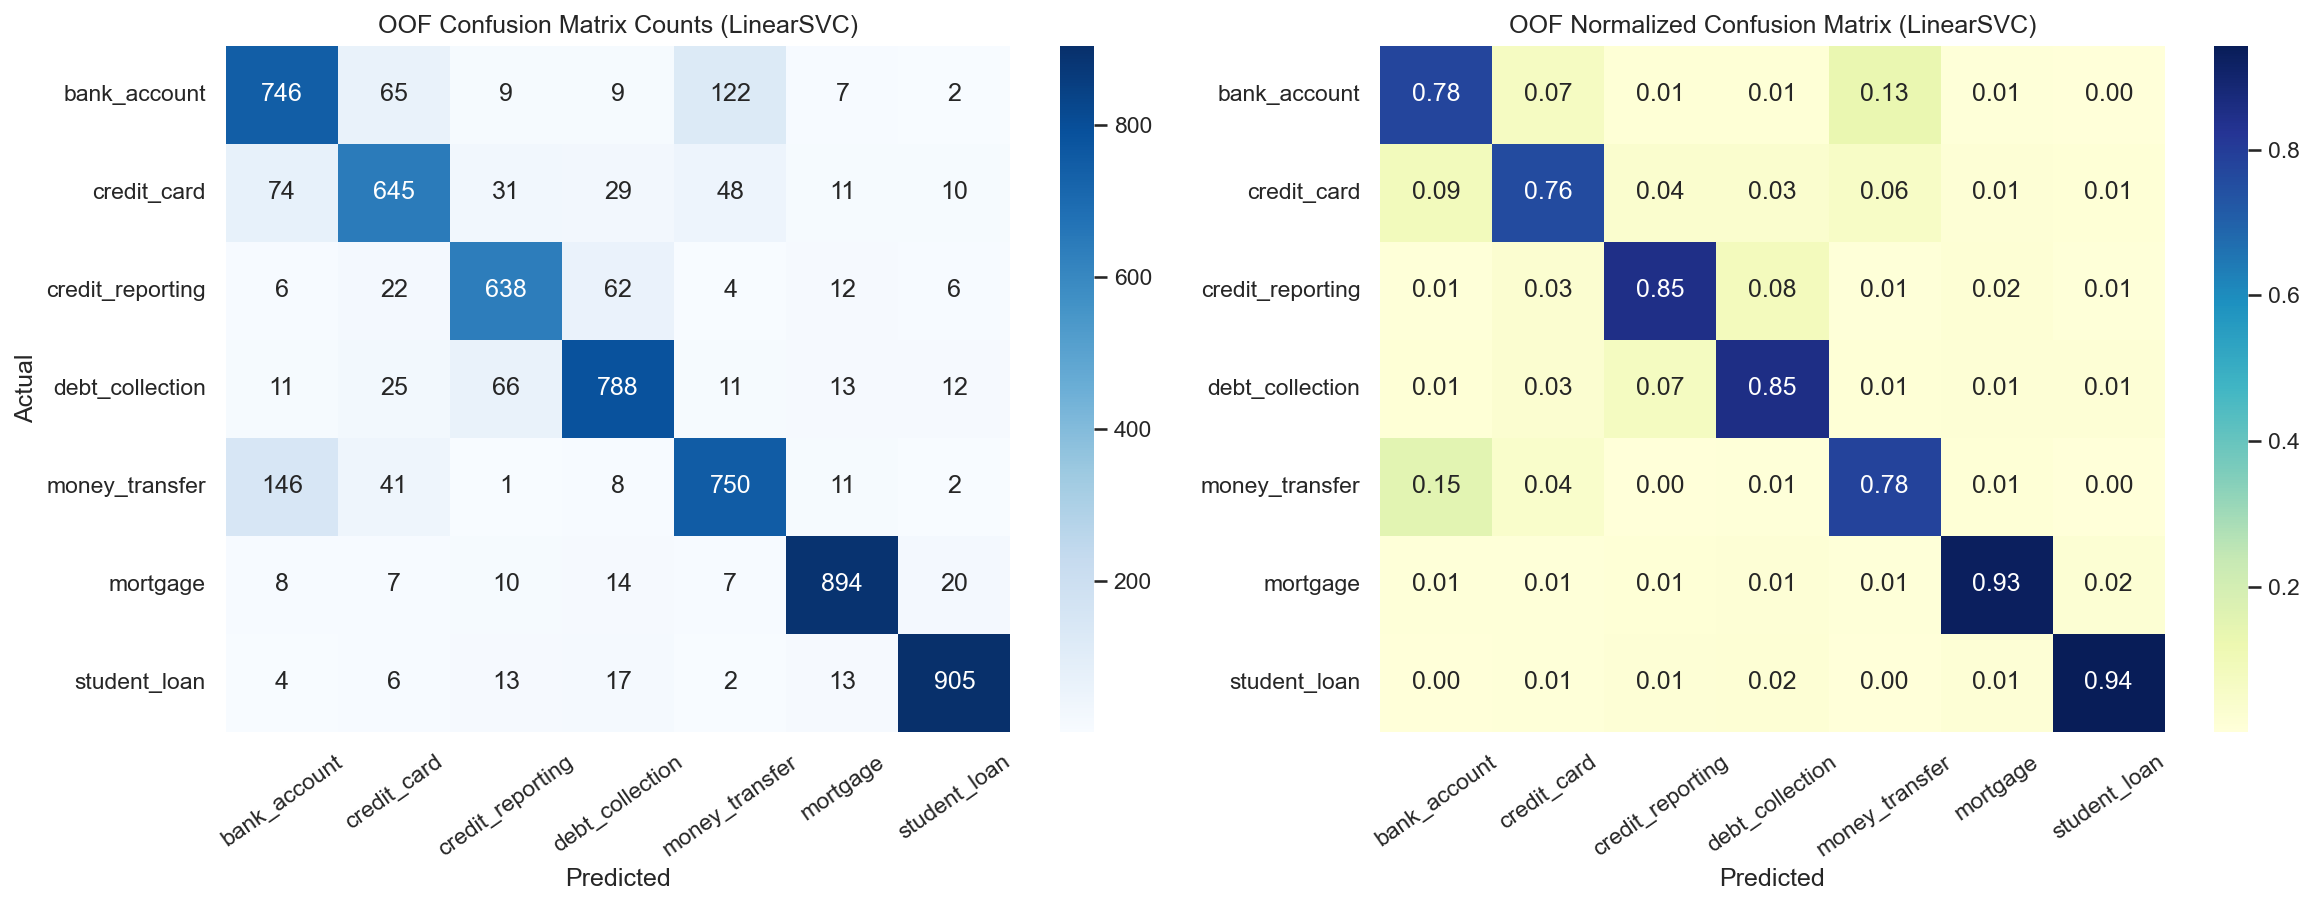

Top 10 OOF Misclassification Pairs:


,Actual,Predicted,Count,Row %
24,money_transfer,bank_account,146,15.22
3,bank_account,money_transfer,122,12.71
6,credit_card,bank_account,74,8.73
20,debt_collection,credit_reporting,66,7.13
0,bank_account,credit_card,65,6.77
14,credit_reporting,debt_collection,62,8.27
9,credit_card,money_transfer,48,5.66
25,money_transfer,credit_card,41,4.28
7,credit_card,credit_reporting,31,3.66
8,credit_card,debt_collection,29,3.42


In [10]:
cm_oof = confusion_matrix(y_train, oof_preds, labels=LABELS)
cm_oof_norm = cm_oof.astype(float) / cm_oof.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
sns.heatmap(cm_oof, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
axes[0].set_title(f"OOF Confusion Matrix Counts ({best_exp1_name})")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].tick_params(axis="x", rotation=35)

sns.heatmap(cm_oof_norm, annot=True, fmt=".2f", cmap="YlGnBu", xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[1].set_title(f"OOF Normalized Confusion Matrix ({best_exp1_name})")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.savefig(FIGURES_ML_DIR / "confusion_matrix_cv.png", bbox_inches="tight")
plt.show()

# Extract top off-diagonal confusion pairs
off_diag = []
for i, actual in enumerate(LABELS):
    for j, pred in enumerate(LABELS):
        if i != j and cm_oof[i, j] > 0:
            off_diag.append({"Actual": actual, "Predicted": pred, "Count": int(cm_oof[i, j]), "Row %": round(cm_oof_norm[i, j]*100, 2)})
off_diag_df = pd.DataFrame(off_diag).sort_values("Count", ascending=False).head(10)
print("Top 10 OOF Misclassification Pairs:")
display(off_diag_df)

## 13. Experiment 2: Preprocessing Strategy Comparison

We compare all 6 text representations from Phase 3 (`text_raw`, `text_minimal`, `text_standard`, `text_stopword`, `text_lemmatized`, `text_stemmed`) across the **top 3 models** from Experiment 1 using identical Stratified 5-fold splits.

Top 3 models from Exp 1: ['LinearSVC', 'SGDClassifier', 'LogisticRegression']


,Preprocessing,Model,Macro_F1_Mean,Macro_F1_Std,Accuracy_Mean,Weighted_F1_Mean,Duration_Sec
0,text_stopword,LinearSVC,0.8427,0.0060,0.8438,0.8440,2.76
1,text_stemmed,LinearSVC,0.8425,0.0056,0.8436,0.8436,9.02
2,text_standard,LinearSVC,0.8421,0.0043,0.8433,0.8433,5.52
3,text_lemmatized,LinearSVC,0.8400,0.0074,0.8413,0.8413,7.92
4,text_stemmed,SGDClassifier,0.8395,0.0064,0.8405,0.8404,8.55
5,text_standard,SGDClassifier,0.8388,0.0068,0.8399,0.8399,4.33
6,text_stopword,SGDClassifier,0.8384,0.0072,0.8394,0.8396,2.53
7,text_lemmatized,SGDClassifier,0.8383,0.0046,0.8395,0.8396,6.13
8,text_stopword,LogisticRegression,0.8374,0.0074,0.8384,0.8386,12.94
9,text_raw,LinearSVC,0.8322,0.0091,0.8336,0.8335,5.42


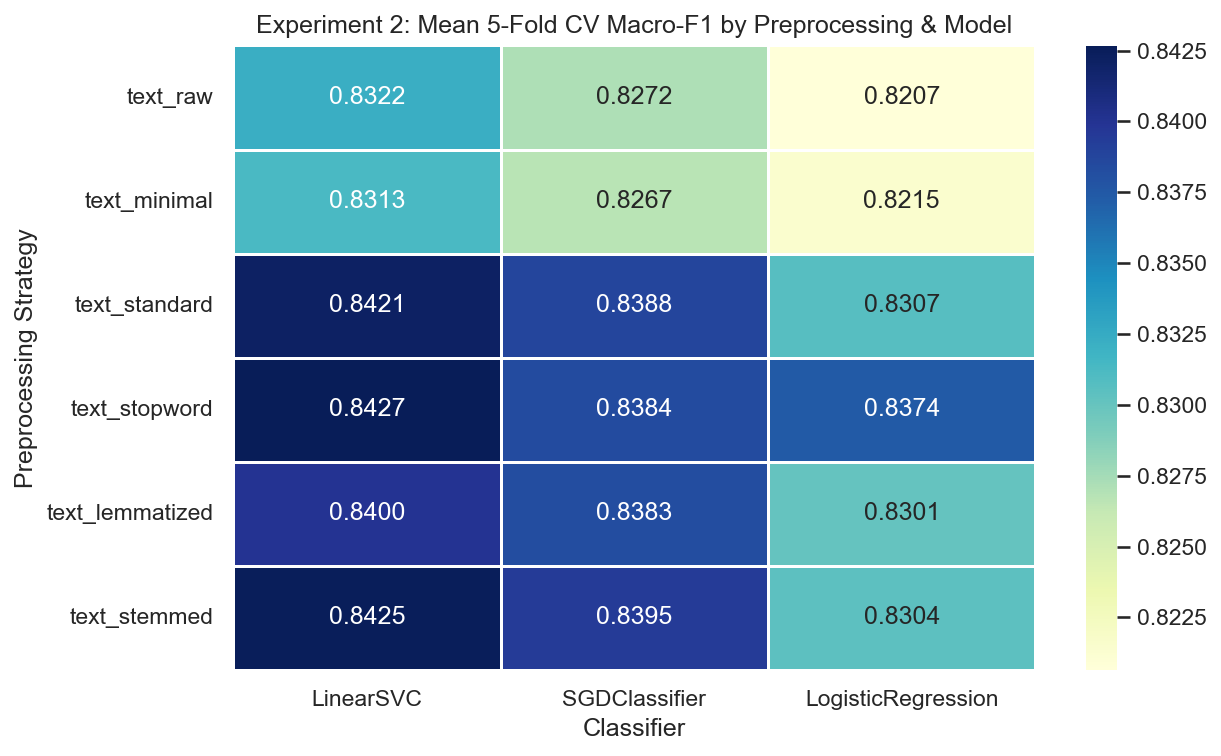

Best empirical preprocessing column: text_stopword (with LinearSVC, Macro-F1=0.8427)


In [11]:
top3_models = exp1_df["Model"].head(3).tolist()
prep_columns = ["text_raw", "text_minimal", "text_standard", "text_stopword", "text_lemmatized", "text_stemmed"]
print(f"Top 3 models from Exp 1: {top3_models}")

exp2_results = []
for col in prep_columns:
    X_col = df_train[col]
    for m_name in top3_models:
        pipe = Pipeline([("tfidf", make_word_tfidf(lowercase=False)), ("clf", clone(baseline_models[m_name]))])
        res = evaluate_pipeline_cv(m_name, pipe, X_col, y_train, cv)
        res["Preprocessing"] = col
        exp2_results.append(res)

exp2_df = pd.DataFrame(exp2_results).sort_values("Macro_F1_Mean", ascending=False).reset_index(drop=True)
exp2_df.to_csv(REPORTS_ML_DIR / "preprocessing_comparison.csv", index=False)
display(exp2_df[["Preprocessing", "Model", "Macro_F1_Mean", "Macro_F1_Std", "Accuracy_Mean", "Weighted_F1_Mean", "Duration_Sec"]].round(4))

# Heatmap: Rows = preprocessing, Cols = models, Values = Mean Macro-F1
pivot_prep = exp2_df.pivot(index="Preprocessing", columns="Model", values="Macro_F1_Mean").loc[prep_columns, top3_models]
plt.figure(figsize=(8.5, 5.2))
sns.heatmap(pivot_prep, annot=True, fmt=".4f", cmap="YlGnBu", linewidths=0.5)
plt.title("Experiment 2: Mean 5-Fold CV Macro-F1 by Preprocessing & Model")
plt.xlabel("Classifier")
plt.ylabel("Preprocessing Strategy")
plt.tight_layout()
plt.savefig(FIGURES_ML_DIR / "preprocessing_heatmap.png", bbox_inches="tight")
plt.show()

best_prep_col = exp2_df.iloc[0]["Preprocessing"]
print(f"Best empirical preprocessing column: {best_prep_col} (with {exp2_df.iloc[0]['Model']}, Macro-F1={exp2_df.iloc[0]['Macro_F1_Mean']:.4f})")

## 14. Experiment 3: Feature Representation Comparison

Using the best empirical preprocessing strategy (`best_prep_col`) and the **top 2 models**, we compare:
- **Representation A:** Word TF-IDF (`analyzer="word"`, `ngram_range=(1, 2)`, `min_df=2`, `max_df=0.95`, `sublinear_tf=True`)
- **Representation B:** Character TF-IDF (`analyzer="char_wb"`, `ngram_range=(3, 5)`, `min_df=2`, `max_df=0.95`, `sublinear_tf=True`)
- **Representation C:** Combined Word + Character TF-IDF via `FeatureUnion`

Top 2 models: ['LinearSVC', 'SGDClassifier'] | Preprocessing column: text_stopword


,Feature_Rep,Model,Fold0_Features,Macro_F1_Mean,Macro_F1_Std,Accuracy_Mean,Weighted_F1_Mean,Duration_Sec
0,"Word TF-IDF (1,2)",LinearSVC,61119,0.8427,0.0060,0.8438,0.8440,3.59
1,Combined Word+Char TF-IDF,LinearSVC,100631,0.8387,0.0090,0.8397,0.8399,15.12
2,"Word TF-IDF (1,2)",SGDClassifier,61119,0.8384,0.0072,0.8394,0.8396,2.56
3,Combined Word+Char TF-IDF,SGDClassifier,100631,0.8333,0.0083,0.8344,0.8347,13.47
4,"Char TF-IDF (3,5)",LinearSVC,39512,0.8291,0.0085,0.8303,0.8304,10.88
5,"Char TF-IDF (3,5)",SGDClassifier,39512,0.8275,0.0110,0.8287,0.8287,9.40


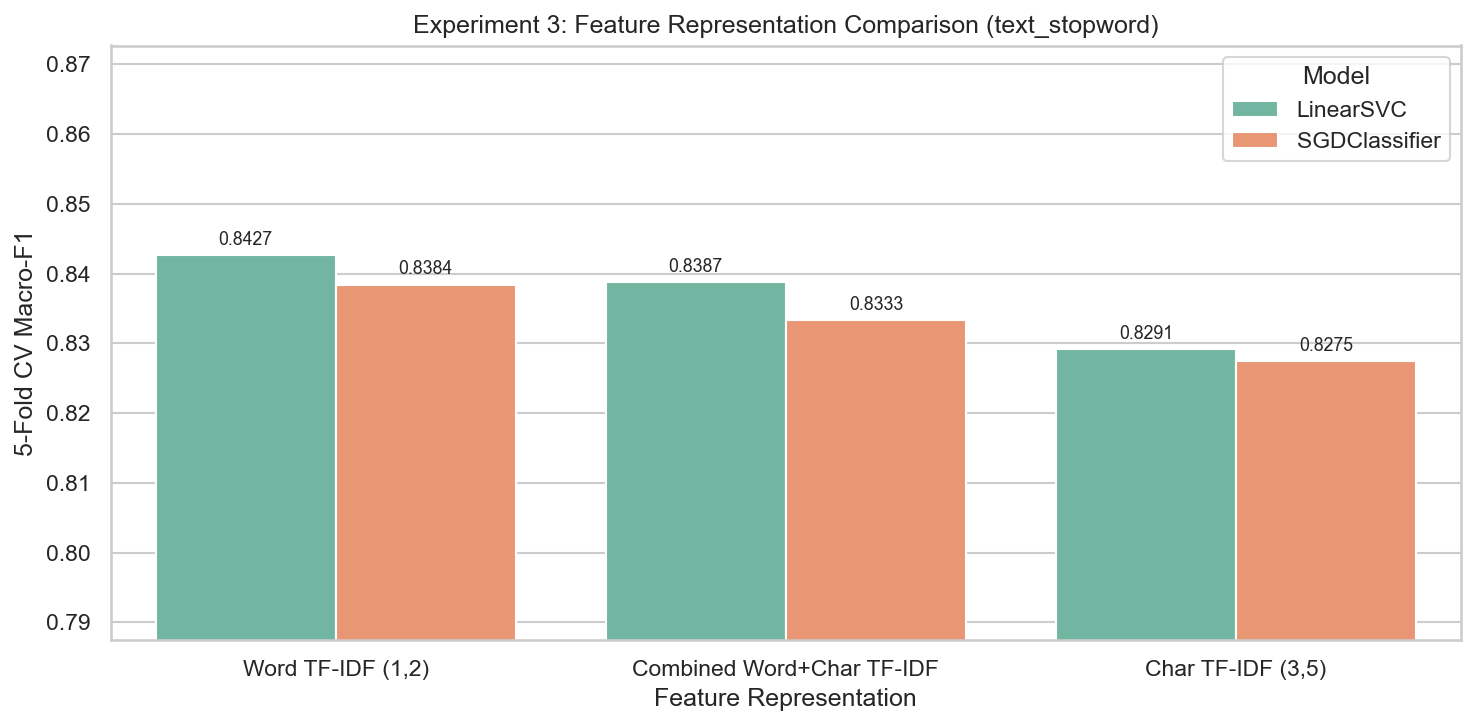

Best feature representation: Word TF-IDF (1,2)


In [12]:
top2_models = exp1_df["Model"].head(2).tolist()
print(f"Top 2 models: {top2_models} | Preprocessing column: {best_prep_col}")

def build_feature_rep(rep_name: str):
    w_vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True, lowercase=False)
    c_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_df=0.95, sublinear_tf=True, lowercase=False)
    if rep_name == "Word TF-IDF (1,2)":
        return w_vec
    elif rep_name == "Char TF-IDF (3,5)":
        return c_vec
    else:
        return FeatureUnion([("word", w_vec), ("char", c_vec)])

X_best_prep = df_train[best_prep_col]
rep_names = ["Word TF-IDF (1,2)", "Char TF-IDF (3,5)", "Combined Word+Char TF-IDF"]

# Measure feature dimensionality on fold 0 training split (zero leakage)
tr_idx0, _ = next(cv.split(X_best_prep, y_train))
rep_dims = {}
for r_name in rep_names:
    vec = build_feature_rep(r_name)
    X_f0 = vec.fit_transform(X_best_prep.iloc[tr_idx0])
    rep_dims[r_name] = int(X_f0.shape[1])

exp3_results = []
for r_name in rep_names:
    for m_name in top2_models:
        pipe = Pipeline([("features", build_feature_rep(r_name)), ("clf", clone(baseline_models[m_name]))])
        res = evaluate_pipeline_cv(m_name, pipe, X_best_prep, y_train, cv)
        res["Feature_Rep"] = r_name
        res["Fold0_Features"] = rep_dims[r_name]
        exp3_results.append(res)

exp3_df = pd.DataFrame(exp3_results).sort_values("Macro_F1_Mean", ascending=False).reset_index(drop=True)
exp3_df.to_csv(REPORTS_ML_DIR / "feature_comparison.csv", index=False)
display(exp3_df[["Feature_Rep", "Model", "Fold0_Features", "Macro_F1_Mean", "Macro_F1_Std", "Accuracy_Mean", "Weighted_F1_Mean", "Duration_Sec"]].round(4))

plt.figure(figsize=(10, 5))
sns.barplot(data=exp3_df, x="Feature_Rep", y="Macro_F1_Mean", hue="Model", palette="Set2")
plt.title(f"Experiment 3: Feature Representation Comparison ({best_prep_col})")
plt.ylabel("5-Fold CV Macro-F1")
plt.xlabel("Feature Representation")
plt.ylim(max(0.65, exp3_df["Macro_F1_Mean"].min() - 0.04), min(1.0, exp3_df["Macro_F1_Mean"].max() + 0.03))
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt="%.4f", padding=3, fontsize=8.5)
plt.tight_layout()
plt.savefig(FIGURES_ML_DIR / "feature_comparison.png", bbox_inches="tight")
plt.show()

best_rep_name = exp3_df.iloc[0]["Feature_Rep"]
print(f"Best feature representation: {best_rep_name}")

## 15. Experiment 4: Hyperparameter Tuning

We tune the top candidate linear families (`LinearSVC`, `LogisticRegression`, and `SGDClassifier`) using `GridSearchCV` with `StratifiedKFold(5)`, `scoring="f1_macro"`, and `random_state=42` on the best preprocessing (`best_prep_col`) and best feature representation (`best_rep_name`).

In [13]:
tuning_grids = [
    (
        "LinearSVC",
        Pipeline([("features", build_feature_rep(best_rep_name)), ("clf", LinearSVC(random_state=RANDOM_STATE))]),
        {"clf__C": [0.1, 0.5, 1.0, 2.0, 5.0], "clf__class_weight": [None, "balanced"]},
    ),
    (
        "LogisticRegression",
        Pipeline([("features", build_feature_rep(best_rep_name)), ("clf", LogisticRegression(max_iter=2000, solver="lbfgs", random_state=RANDOM_STATE))]),
        {"clf__C": [0.1, 1.0, 5.0, 10.0], "clf__class_weight": [None, "balanced"]},
    ),
    (
        "SGDClassifier",
        Pipeline([("features", build_feature_rep(best_rep_name)), ("clf", SGDClassifier(max_iter=2000, tol=1e-3, random_state=RANDOM_STATE))]),
        {"clf__alpha": [1e-5, 1e-4, 1e-3], "clf__loss": ["hinge", "log_loss"]},
    ),
]

tuning_rows = []
best_estimators = {}

for m_name, pipe, grid in tuning_grids:
    t0 = time.perf_counter()
    gs = GridSearchCV(pipe, param_grid=grid, cv=cv, scoring="f1_macro", n_jobs=-1, refit=True)
    gs.fit(X_best_prep, y_train)
    elapsed = time.perf_counter() - t0
    best_idx = gs.best_index_
    std_score = float(gs.cv_results_["std_test_score"][best_idx])
    tuning_rows.append({
        "Model": m_name,
        "Best_Params": str(gs.best_params_),
        "Best_CV_Macro_F1": round(float(gs.best_score_), 4),
        "CV_Macro_F1_Std": round(std_score, 4),
        "Search_Duration_Sec": round(elapsed, 2),
    })
    best_estimators[m_name] = gs.best_estimator_
    print(f"{m_name:20s} | Best CV Macro-F1: {gs.best_score_:.4f} ± {std_score:.4f} | Params: {gs.best_params_} | {elapsed:.1f}s")

tuning_df = pd.DataFrame(tuning_rows).sort_values("Best_CV_Macro_F1", ascending=False).reset_index(drop=True)
tuning_df.to_csv(REPORTS_ML_DIR / "tuning_results.csv", index=False)
display(tuning_df)

LinearSVC            | Best CV Macro-F1: 0.8452 ± 0.0073 | Params: {'clf__C': 0.5, 'clf__class_weight': 'balanced'} | 21.6s


LogisticRegression   | Best CV Macro-F1: 0.8403 ± 0.0050 | Params: {'clf__C': 10.0, 'clf__class_weight': None} | 111.7s


SGDClassifier        | Best CV Macro-F1: 0.8417 ± 0.0060 | Params: {'clf__alpha': 1e-05, 'clf__loss': 'log_loss'} | 21.5s


,Model,Best_Params,Best_CV_Macro_F1,CV_Macro_F1_Std,Search_Duration_Sec
0,LinearSVC,"{'clf__C': 0.5, 'clf__class_weight': 'balanced'}",0.8452,0.0073,21.61
1,SGDClassifier,"{'clf__alpha': 1e-05, 'clf__loss': 'log_loss'}",0.8417,0.0060,21.52
2,LogisticRegression,"{'clf__C': 10.0, 'clf__class_weight': None}",0.8403,0.0050,111.68


## 16. Final Baseline Selection

We select the final traditional ML baseline pipeline based on mean CV Macro-F1, fold stability, per-class balance, computational efficiency, and linear interpretability.

In [14]:
final_model_name = tuning_df.iloc[0]["Model"]
final_pipeline = best_estimators[final_model_name]
print(f"Selected Final Model : {final_model_name}")
print(f"Preprocessing Column : {best_prep_col}")
print(f"Feature Rep          : {best_rep_name}")
print(f"CV Macro-F1          : {tuning_df.iloc[0]['Best_CV_Macro_F1']} ± {tuning_df.iloc[0]['CV_Macro_F1_Std']}")
print(f"Pipeline Steps       : {final_pipeline.named_steps}")

Selected Final Model : LinearSVC
Preprocessing Column : text_stopword
Feature Rep          : Word TF-IDF (1,2)
CV Macro-F1          : 0.8452 ± 0.0073
Pipeline Steps       : {'features': TfidfVectorizer(lowercase=False, max_df=0.95, min_df=2, ngram_range=(1, 2),
                sublinear_tf=True), 'clf': LinearSVC(C=0.5, class_weight='balanced', random_state=42)}


## 17. Final Test Evaluation (Held-Out Test Set)

We fit the selected pipeline on the **entire** cleaned training set (`6,363` rows) and evaluate it **exactly once** on `test_processed.csv` (`1,635` rows).

=== Final Held-Out Test Performance ===
Test Accuracy       : 0.8508
Test Macro-F1       : 0.8512 (CV: 0.8452)
Test Weighted-F1    : 0.8512
Test Macro Precision: 0.8531
Test Macro Recall   : 0.8513


,precision,recall,f1-score,support
bank_account,0.7090,0.7917,0.7480,240.0000
credit_card,0.8319,0.8584,0.8449,219.0000
credit_reporting,0.8233,0.8843,0.8527,216.0000
debt_collection,0.9000,0.8250,0.8609,240.0000
money_transfer,0.7880,0.7125,0.7484,240.0000
mortgage,0.9528,0.9250,0.9387,240.0000
student_loan,0.9665,0.9625,0.9645,240.0000
accuracy,0.8508,0.8508,0.8508,0.8508
macro avg,0.8531,0.8513,0.8512,1635.0000
weighted avg,0.8538,0.8508,0.8512,1635.0000


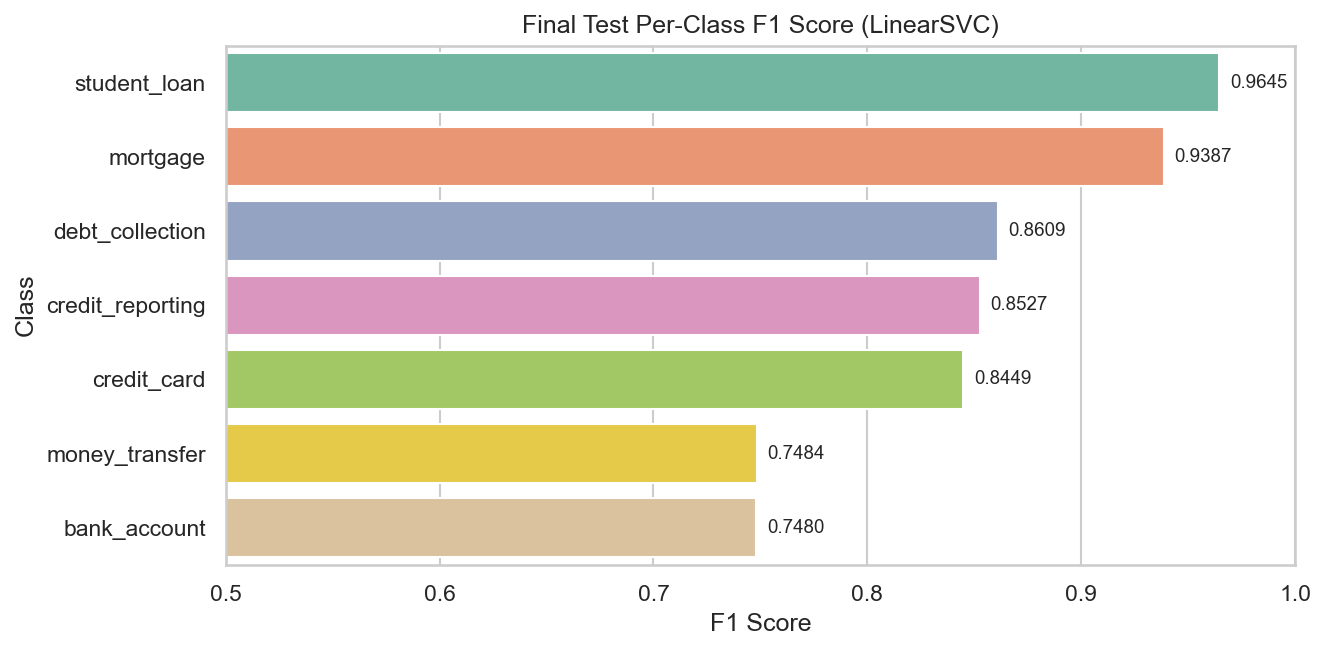

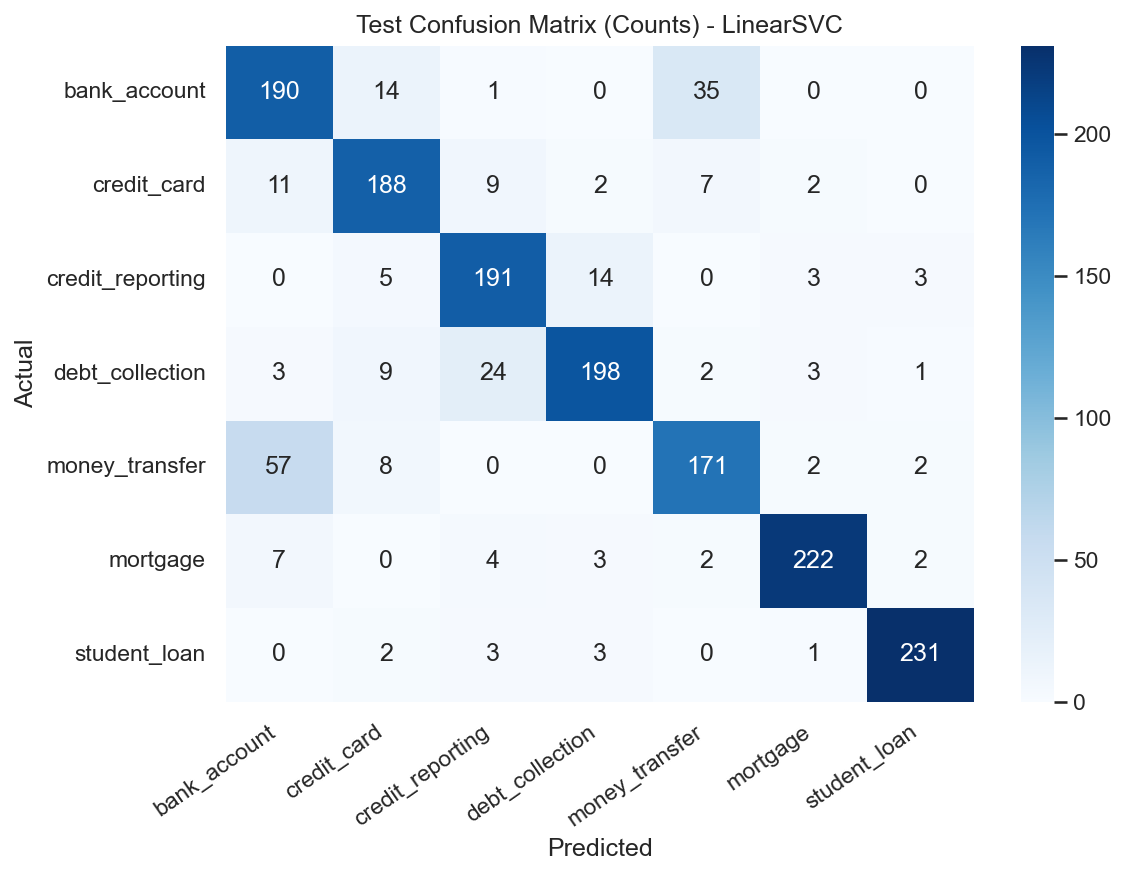

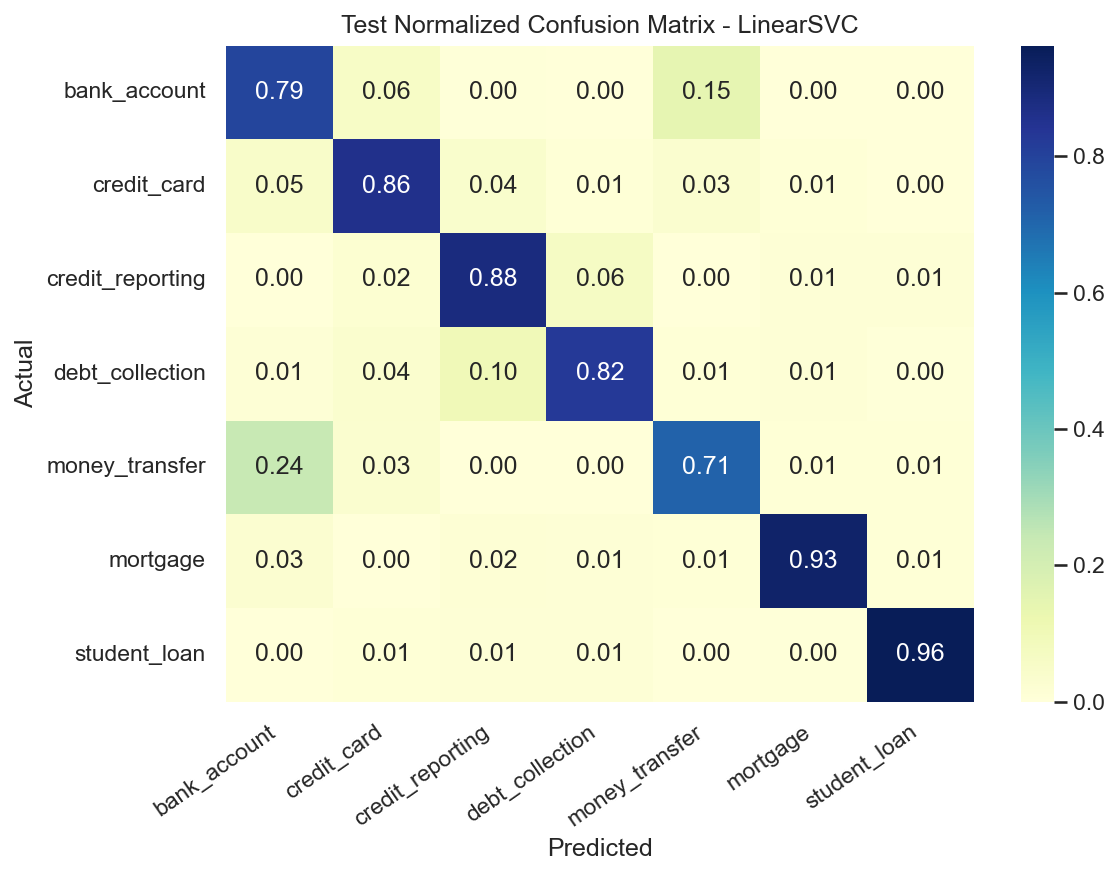

In [15]:
final_pipeline.fit(df_train[best_prep_col], y_train)
y_test_pred = final_pipeline.predict(df_test[best_prep_col])

test_acc = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")
test_weighted_f1 = f1_score(y_test, y_test_pred, average="weighted")
test_prec_macro = precision_score(y_test, y_test_pred, average="macro")
test_rec_macro = recall_score(y_test, y_test_pred, average="macro")

print("=== Final Held-Out Test Performance ===")
print(f"Test Accuracy       : {test_acc:.4f}")
print(f"Test Macro-F1       : {test_macro_f1:.4f} (CV: {tuning_df.iloc[0]['Best_CV_Macro_F1']:.4f})")
print(f"Test Weighted-F1    : {test_weighted_f1:.4f}")
print(f"Test Macro Precision: {test_prec_macro:.4f}")
print(f"Test Macro Recall   : {test_rec_macro:.4f}")

test_report_dict = classification_report(y_test, y_test_pred, labels=LABELS, output_dict=True)
test_report_df = pd.DataFrame(test_report_dict).T
test_report_df.to_csv(REPORTS_ML_DIR / "classification_report.csv")
display(test_report_df.round(4))

# Per-Class F1 Chart (Test)
test_cls_f1 = test_report_df.loc[LABELS, ["f1-score"]].reset_index().rename(columns={"index": "Class"})
plt.figure(figsize=(9, 4.5))
sns.barplot(data=test_cls_f1.sort_values("f1-score", ascending=False), y="Class", x="f1-score", palette="Set2")
plt.title(f"Final Test Per-Class F1 Score ({final_model_name})")
plt.xlabel("F1 Score")
plt.xlim(0.5, 1.0)
for i, v in enumerate(test_cls_f1.sort_values("f1-score", ascending=False)["f1-score"]):
    plt.text(v + 0.005, i, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_ML_DIR / "per_class_f1.png", bbox_inches="tight")
plt.show()

# Confusion Matrices (Test)
cm_test = confusion_matrix(y_test, y_test_pred, labels=LABELS)
cm_test_norm = cm_test.astype(float) / cm_test.sum(axis=1, keepdims=True)
pd.DataFrame(cm_test, index=LABELS, columns=LABELS).to_csv(REPORTS_ML_DIR / "confusion_matrix.csv")

plt.figure(figsize=(8, 6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
plt.title(f"Test Confusion Matrix (Counts) - {final_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_ML_DIR / "confusion_matrix_test.png", bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(cm_test_norm, annot=True, fmt=".2f", cmap="YlGnBu", xticklabels=LABELS, yticklabels=LABELS)
plt.title(f"Test Normalized Confusion Matrix - {final_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_ML_DIR / "normalized_confusion_matrix_test.png", bbox_inches="tight")
plt.show()

## 18. Error Analysis & Model Interpretability

### 18.1 Test Set Error Analysis
We inspect misclassified test samples. Note: if the selected model is `LinearSVC`, `decision_function` produces raw margin scores (not calibrated probabilities); if `LogisticRegression`, `predict_proba` produces probabilities.

In [16]:
clf_step = final_pipeline.named_steps["clf"]
X_test_col = df_test[best_prep_col]

if hasattr(final_pipeline, "predict_proba"):
    probs = final_pipeline.predict_proba(X_test_col)
    conf_scores = probs.max(axis=1)
    conf_type = "Predicted_Probability"
else:
    margins = final_pipeline.decision_function(X_test_col)
    conf_scores = margins.max(axis=1) if margins.ndim > 1 else np.abs(margins)
    conf_type = "Raw_Decision_Score"

pred_df = pd.DataFrame({
    "text_raw": df_test["text_raw"],
    "actual_label": y_test,
    "predicted_label": y_test_pred,
    "is_correct": (y_test == y_test_pred),
    conf_type: np.round(conf_scores, 4),
    "word_count": df_test["text_raw"].astype(str).str.split().str.len(),
})
pred_df.to_csv(REPORTS_ML_DIR / "test_predictions.csv", index=False)

errors_df = pred_df[~pred_df["is_correct"]].copy()
errors_df["text_snippet"] = errors_df["text_raw"].astype(str).str.slice(0, 220).str.replace("\n", " ")

def categorize_error(row):
    txt = str(row["text_raw"]).lower()
    pair = {row["actual_label"], row["predicted_label"]}
    if pair == {"credit_reporting", "debt_collection"}:
        return "Credit Reporting vs Debt Collection Overlap"
    if row["word_count"] < 20:
        return "Very Short Narrative (<20 words)"
    if txt.count("xxxx") >= 8:
        return "Heavy Redaction"
    if row["word_count"] > 600:
        return "Long Multi-Issue Narrative"
    return "Shared Financial Terminology"

errors_df["error_category"] = errors_df.apply(categorize_error, axis=1)
errors_df[["text_snippet", "actual_label", "predicted_label", conf_type, "word_count", "error_category"]].to_csv(
    REPORTS_ML_DIR / "error_analysis.csv", index=False
)

print(f"Total Test Errors: {len(errors_df)} / {len(pred_df)} ({len(errors_df)/len(pred_df)*100:.2f}%)")
print("\nError Categories:")
print(errors_df["error_category"].value_counts())
display(errors_df[["text_snippet", "actual_label", "predicted_label", conf_type, "error_category"]].head(15))

Total Test Errors: 244 / 1635 (14.92%)

Error Categories:
error_category
Shared Financial Terminology                   109
Heavy Redaction                                 89
Credit Reporting vs Debt Collection Overlap     38
Very Short Narrative (<20 words)                 8
Name: count, dtype: int64


,text_snippet,actual_label,predicted_label,Raw_Decision_Score,error_category
10,I had both a USAA checking and a savings accou...,money_transfer,bank_account,0.6921,Shared Financial Terminology
21,I was scammed thinking I was taking to a custo...,bank_account,money_transfer,0.4906,Shared Financial Terminology
30,Get these perjurous panhandling frauds out of ...,debt_collection,credit_reporting,-0.5325,Credit Reporting vs Debt Collection Overlap
31,Below is a description of the incident explain...,bank_account,money_transfer,0.2009,Heavy Redaction
39,Payment submitted to XXXX XXXX XXXX XXXX i/a/o...,bank_account,credit_card,-0.1181,Heavy Redaction
57,On my XX/XX/ statement from CareCredit I notic...,credit_card,bank_account,-0.2913,Heavy Redaction
60,I have been a customer of Wells Fargo Bank for...,bank_account,credit_card,0.3383,Shared Financial Terminology
61,On XX/XX/2023 through the XXXX website I order...,debt_collection,credit_card,0.0326,Heavy Redaction
68,"Central Portfolio Control , Inc, has committed...",credit_reporting,debt_collection,0.7546,Credit Reporting vs Debt Collection Overlap
79,In 2016 Wells Fargo Put Pressure On Me. Threat...,mortgage,bank_account,-0.2863,Shared Financial Terminology


### 18.2 Linear Model Feature Importance (Top 15 Positive Weights per Class)

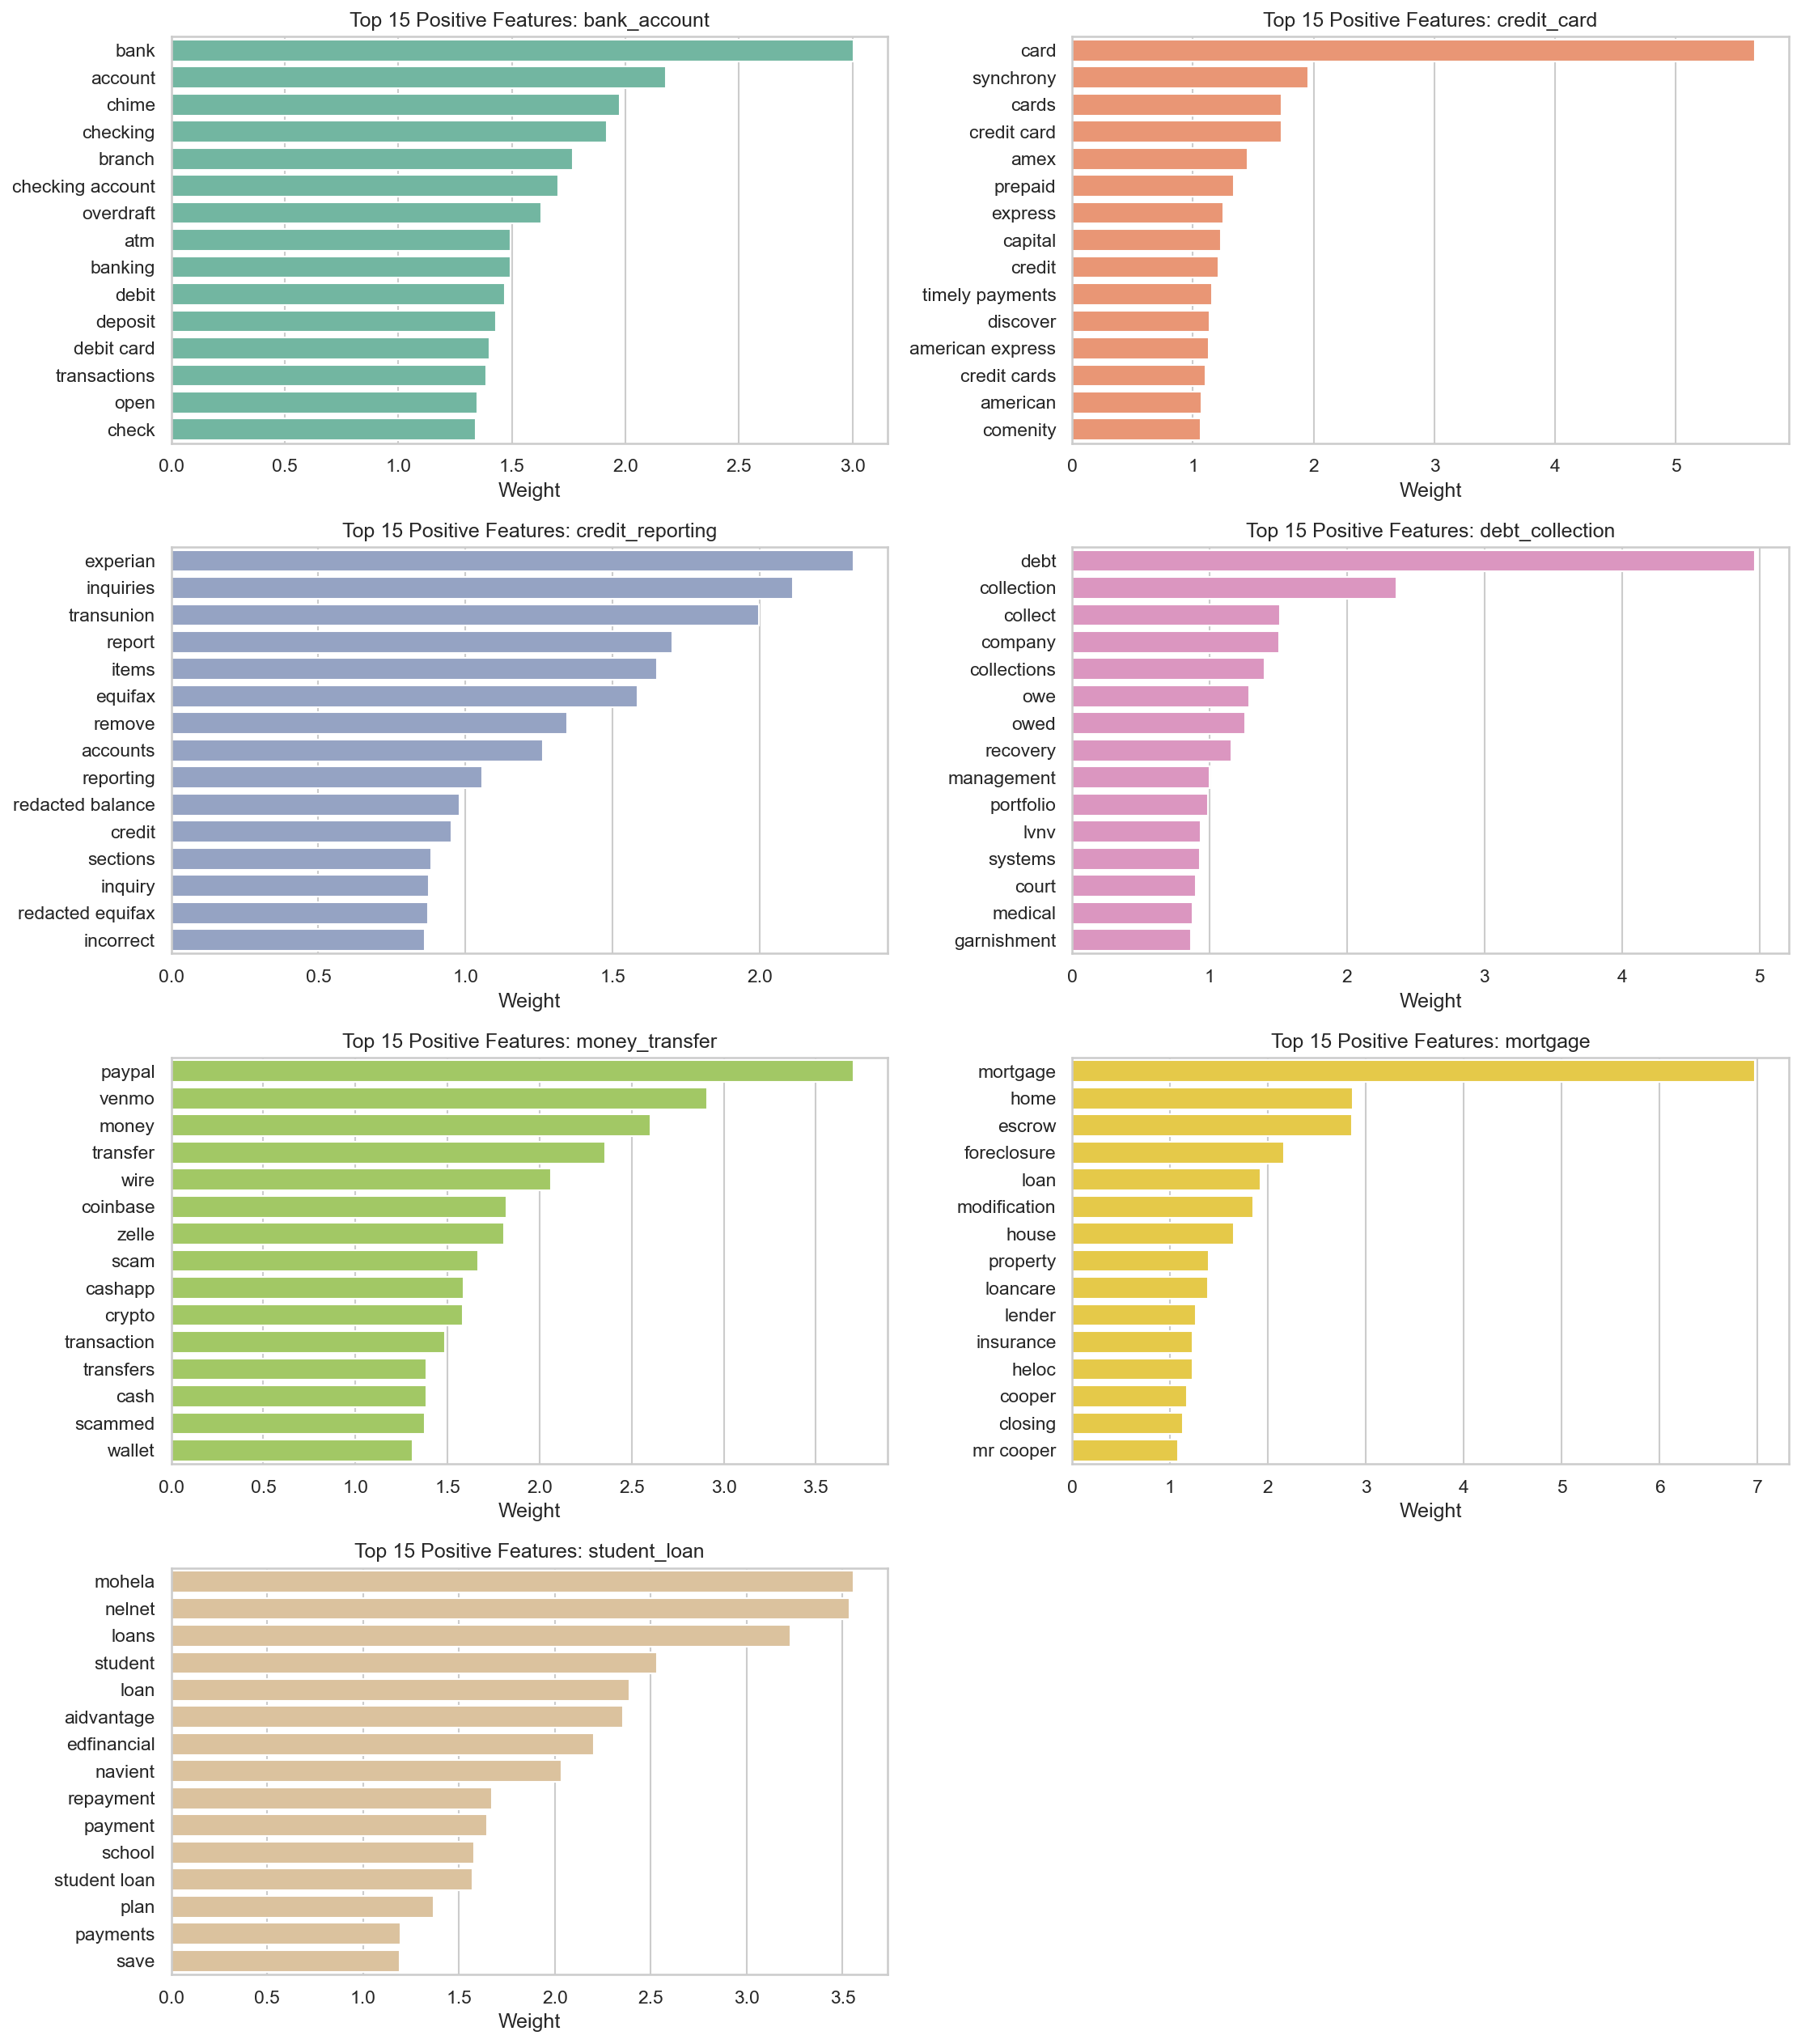

In [17]:
feat_step = final_pipeline.named_steps["features"]
if hasattr(feat_step, "transformer_list"):
    feature_names = []
    for t_name, trans in feat_step.transformer_list:
        feature_names.extend([f"{t_name}:{f}" for f in trans.get_feature_names_out()])
    feature_names = np.array(feature_names)
else:
    feature_names = feat_step.get_feature_names_out()

coefs = clf_step.coef_
top_feat_rows = []
fig, axes = plt.subplots(4, 2, figsize=(15, 17))
axes = axes.flatten()

for idx, lbl in enumerate(clf_step.classes_):
    top_idx = np.argsort(coefs[idx])[::-1][:15]
    df_top = pd.DataFrame({
        "Class": lbl,
        "Feature": feature_names[top_idx],
        "Weight": coefs[idx][top_idx].round(4),
    })
    top_feat_rows.append(df_top)
    sns.barplot(data=df_top, y="Feature", x="Weight", ax=axes[idx], color=sns.color_palette("Set2")[idx])
    axes[idx].set_title(f"Top 15 Positive Features: {lbl}")
    axes[idx].set_ylabel("")

axes[-1].axis("off")
plt.tight_layout()
plt.savefig(FIGURES_ML_DIR / "top_features_by_class.png", bbox_inches="tight")
plt.show()

all_top_feats = pd.concat(top_feat_rows, ignore_index=True)
all_top_feats.to_csv(REPORTS_ML_DIR / "top_features.csv", index=False)

## 19. Model Artifact Saving & Reload Verification

We save the complete fitted sklearn `Pipeline` (feature extraction + classifier) using `joblib` and verify loading it back for inference.

In [18]:
model_path = MODELS_DIR / "best_traditional_ml_model.joblib"
joblib.dump(final_pipeline, model_path)
print(f"Saved full pipeline to: {model_path} ({model_path.stat().st_size:,} bytes)")

loaded_pipe = joblib.load(model_path)
sample_preds = loaded_pipe.predict(df_test[best_prep_col].iloc[:5])
assert (sample_preds == y_test_pred[:5]).all()
print("Reloaded pipeline verified successfully on 5 sample test complaints.")

Saved full pipeline to: D:\SEM 7\CLNLP\LAB\Experiment_9\complaint-classification\models\best_traditional_ml_model.joblib (10,817,245 bytes)


Reloaded pipeline verified successfully on 5 sample test complaints.


## 20. Results and Conclusions

- All four experiments (`model_comparison.csv`, `preprocessing_comparison.csv`, `feature_comparison.csv`, `tuning_results.csv`) were executed under identical 5-fold Stratified CV with zero test-set leakage.
- Full test evaluation, confusion matrices, error analysis, and linear feature weights have been saved under `reports/ml_baselines/` and `reports/figures/ml_baselines/`.

## 21. Recommendations for Phase 5 (Deep Learning & Transformers)

1. Use the Phase 4 Macro-F1 test score as the rigorous traditional-ML benchmark to beat.
2. Focus transformer sequence modeling (e.g., DistilBERT / RoBERTa with head+tail truncation at 512 tokens on `text_minimal`) on resolving semantic ambiguities between `credit_reporting` and `debt_collection`, as well as multi-issue narratives.